*© Sabrine Bendimerad · [sbendimerad.github.io](https://sbendimerad.github.io) · Licence [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/): you may share and adapt this material with credit, for non-commercial use, under the same licence. Datasets keep their own licences.*

# Linear regressions

In this section we will focus on **regression models**, that is, any machine learning model that estimates a numerical and **continuous** target variable. We will use concrete examples such as real estate prices (in the exercises, the California housing dataset).



## What will you learn in this course? 🧐🧐

This course will give you the theoretical background you need to understand linear regression models.

* Simple linear regressions
    * Definitions
        * Dependent variables
        * Independent Variables
        * Coefficient
        * Constant
        * Residual
* Assumptions behind linear regression
    * Linearity
    * Homoscedasticity
    * Independence of residuals
* Estimation
    * The ordinary least squares method (commonly referred to as OLS)
        * Definition
* Multiple linear regression
    * Definition
        * Plurality of independent variables
    * Normalizing the variables
    * Mathematical notation of the problem
    * Variance/Covariance Matrix
* Assumptions for multiple linear regression
    * Everything in simple linear regression plus NO collinearity
    * Dummy Variables
        * Reminder: Categorical variables
        * Encode categorical variables
        * The dummy variable trap
* Final remarks

Each concept of this lesson comes with a small demo 🔬 on data. Most of them use the California housing dataset of the exercises: each row is a district of California, and the target `MedHouseVal` is the median house value of the district (in hundreds of thousands of dollars). The next cell loads the libraries and the data.

In [ ]:
import numpy as np
import pandas as pd
import plotly.express as px
from plotly.subplots import make_subplots
from sklearn.linear_model import LinearRegression
import plotly.io as pio
import plotly.graph_objects as go
pio.templates["course"] = go.layout.Template(layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"])
pio.templates.default = "plotly_white+course"

housing = pd.read_csv("data/california_housing_market.csv")
print(housing.shape)
housing.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## Simple linear regressions 🧸

### Definition

Simple linear regression models are based on the following linear equation:

$$
Y = \beta_{0} + \beta_{1}X_1 + \epsilon
$$

Here, $Y$ represents the target variable, i.e. the variable whose value we wish to estimate, and $X_1$ is the explanatory variable we have chosen to estimate it. $\beta_0$, $\beta_{1}$ and $\epsilon$ are respectively:
* the intercept (i.e. the value of $Y$ when $X_1$ is 0);
* the coefficient associated with $X_1$: it is the parameter of the model that measures the influence of $X_1$ on $Y$ (if $X_1$ increases by 1, $Y$ increases by $\beta_{1}$);
* the error, or residual, of the model.

The above equation represents a statistical model: it is true on average but does not claim to be exact, which explains the presence of the residual $\epsilon$.

Given the samples in your dataset (see the scatter plot below), your model finds the line that comes as close as possible to all the dots on average. Here's what it looks like visually:

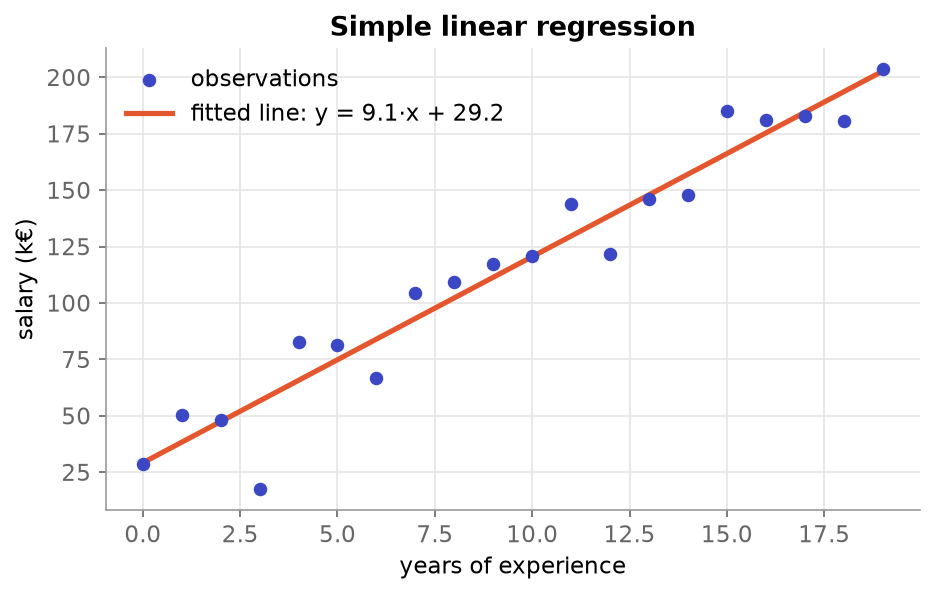

#### Dependent variables

In Machine Learning, we always distinguish between the **dependent variable/target variable** and **independent variables/explanatory variables.** The dependent variable is the element you are trying to predict. In the equation above, this corresponds to $Y$.

#### Independent Variables

The independent variables, represented by $X_i$ ($i$ is an index that indicates the position of the column in the dataset), are the predictors used to determine the value of $Y$. For example, if we try to predict someone's salary based on their years of experience, the independent variable $X_i$ is the number of years of experience.

#### Coefficient

The $\beta_{1}$ coefficient represents the _slope_ of the regression line, or the weight your independent variable has in your equation. As mentioned before, the practical interpretation of $\beta_1$ is the following: if $X_1$ increases by $1$, $Y$ is **expected** to increase by $\beta_1$. The word **expected** is really important here. Remember that any machine learning model is meant to be statistically as good as possible: it must perform best on average across all the training samples, and it does not necessarily predict each individual sample perfectly.

#### Constant

Finally, the constant $\beta_{0}$ represents where your line starts, when $X_1 = 0$. When predicting salaries from years of experience, even with 0 years of experience ($X_1 = 0$), the starting salary is expected to be different from 0.

#### Residual

The residual, often denoted $\epsilon$, corresponds to the error. It represents all the information that is not explained by the model. The error is often assumed to follow a particular probability distribution, which justifies modeling the data with specific kinds of machine learning models.

#### See it with data 🔬: a simple linear regression on real data

Let's explain the median house value (`MedHouseVal`) with a single variable: the median income of the district (`MedInc`, in tens of thousands of dollars). We fit the model on all the districts, then draw the line, together with the residuals of 40 districts (the vertical segments between each point and the line).

In [ ]:
X = housing[["MedInc"]]
y = housing["MedHouseVal"]
simple = LinearRegression().fit(X, y)
print(f"beta_0 (intercept) = {simple.intercept_:.3f}")
print(f"beta_1 (MedInc)    = {simple.coef_[0]:.3f}")

beta_0 (intercept) = 0.451
beta_1 (MedInc)    = 0.418


In [ ]:
sample = housing.sample(40, random_state=1)
pred = simple.predict(sample[["MedInc"]])
fig = px.scatter(housing.sample(2000, random_state=0), x="MedInc", y="MedHouseVal", opacity=0.3,
                 title="House value vs income: the regression line and some residuals",
                 labels={"MedInc": "Median income (tens of k$)", "MedHouseVal": "Median house value (100 k$)"})
grid = np.linspace(0, 15, 2)
fig.add_scatter(x=grid, y=simple.intercept_ + simple.coef_[0] * grid, mode="lines", name="regression line")
for xi, yi, pi in zip(sample["MedInc"], sample["MedHouseVal"], pred):
    fig.add_scatter(x=[xi, xi], y=[yi, pi], mode="lines", line=dict(color="#E4572E", width=1), showlegend=False)
fig.show()

The model found $\beta_0 = 0.451$ and $\beta_1 = 0.418$. In plain words: when the median income of a district increases by 1 unit (10,000 dollars), the median house value is **expected** to increase by 0.418 units (about 41,800 dollars). The red segments are the residuals $\epsilon$: some are large, because income alone can't explain everything (location, house age... are missing from this simple model).

## Assumptions behind linear regression ☝️

When building an ML model, you should be aware of the assumptions your model needs to work well. Otherwise, you may get poor performance. Remember that traditional machine learning is based on statistics, a branch of mathematics, which is an **exact** science. Therefore, all the models we will study in this module are backed by statistical theory and mathematical proofs that define the theoretical context in which the model can be optimized with certainty. In practice, these assumptions are very often not true. However, in most cases, models can still be used and give useful results even when not all assumptions hold. The assumptions needed for a simple linear regression model are the following:

### Linearity

The first assumption is simple: your points need to roughly follow a straight line. In other words, your dependent variable must vary linearly as your independent variables increase.

### Homoscedasticity

If the first assumption holds and your samples follow a linear dependence between $Y$ and $X_1$, homoscedasticity adds an assumption on the statistical distribution of the residual $\epsilon$. Homoscedasticity means that your residuals have a constant variance across all possible values of $Y$. If $\epsilon$ takes small values when $Y$ is small and large values when $Y$ is large, then homoscedasticity does not hold.

In theory, this assumption is important to mathematically solve the linear regression equation we will introduce. However, if it does not hold, your model can still prove useful in practice.

### Independence of residuals

The residuals need to be independent of each other. Independence is very difficult to verify in practice, so it is often replaced with the absence of autocorrelation (autocorrelation means correlation with itself). For example, if the residuals for small values of $Y$ tend to all be negative and the residuals for larger values of $Y$ tend to all be positive, this indicates autocorrelation of the residuals, which we want to avoid.

:::tip Intuition
Residuals should look like pure noise: no shape, no trend, the same spread everywhere. If you can see a pattern in the residuals, it means there is still some structure in the data that the model did not capture (a curve, a spread that grows...). The best way to check is to plot the residuals against the predictions.
:::

#### See it with data 🔬: residual plots, good and bad

We simulate three datasets of 300 points where we know the truth, fit a linear regression on each, and plot the residuals against the predicted values:
1. a linear relation with constant noise: all assumptions hold;
2. a curved relation: linearity is violated;
3. a noise that grows with $X$: homoscedasticity is violated.

In [ ]:
rng = np.random.default_rng(42)
x = rng.uniform(0, 10, 300)
datasets = {
    "1. Assumptions hold": 2 + 3 * x + rng.normal(0, 2, 300),
    "2. Curved relation": 2 + 0.5 * x**2 + rng.normal(0, 2, 300),
    "3. Growing noise": 2 + 3 * x + rng.normal(0, 0.6 * x, 300),
}
fig = make_subplots(rows=1, cols=3, subplot_titles=list(datasets))
for k, (name, y_sim) in enumerate(datasets.items(), start=1):
    m = LinearRegression().fit(x.reshape(-1, 1), y_sim)
    fitted = m.predict(x.reshape(-1, 1))
    fig.add_scatter(x=fitted, y=y_sim - fitted, mode="markers", marker=dict(size=4), showlegend=False, row=1, col=k)
    fig.add_hline(y=0, line_dash="dash", line_color="#999999", row=1, col=k)
fig.update_xaxes(title_text="Predicted value")
fig.update_yaxes(title_text="Residual", col=1)
fig.update_layout(title="Residuals vs predictions for three simulated datasets")
fig.show()

The plots can be summarized with two numbers: the spread (standard deviation) of the residuals for the smallest and the largest half of $X$, and the correlation between each residual and the next one (when points are sorted by $X$), a measure of autocorrelation.

In [ ]:
order = np.argsort(x)
for name, y_sim in datasets.items():
    m = LinearRegression().fit(x.reshape(-1, 1), y_sim)
    res = (y_sim - m.predict(x.reshape(-1, 1)))[order]
    low, high = res[:150].std(), res[150:].std()
    autocorr = np.corrcoef(res[:-1], res[1:])[0, 1]
    print(f"{name:22s} spread small X = {low:.2f}  spread large X = {high:.2f}  autocorrelation = {autocorr:.2f}")

1. Assumptions hold    spread small X = 2.05  spread large X = 1.99  autocorrelation = -0.09
2. Curved relation     spread small X = 3.76  spread large X = 3.88  autocorrelation = 0.74
3. Growing noise       spread small X = 1.85  spread large X = 4.25  autocorrelation = -0.00


In plot 1, the residuals form a shapeless band around 0, with the same spread everywhere (2.05 vs 1.99) and no autocorrelation (-0.09): this is what we want to see. In plot 2, the residuals draw a U shape: the line is too high in the middle and too low at both ends. Neighbouring residuals have the same sign, hence a strong autocorrelation (0.74): this is the pattern described in "Independence of residuals", and here it comes from a violated linearity assumption. In plot 3, the residuals open like a funnel: their spread goes from 1.85 for small $X$ to 4.25 for large $X$, so homoscedasticity is violated. The model still finds a sensible line, but its errors are much bigger for some observations than for others.

## Estimation 🔧

Estimation techniques are the methods we use to calculate the optimal parameters of the model, so that the residuals are as small as possible across all the data. Here we will introduce one technique to optimize a simple linear regression model. You do not need to know it by heart, but you should understand the general logic behind it, which roughly goes as follows: we choose a function, directly linked to the model's equation, that needs to be minimized or maximized. This function is called the loss function when we minimize it, and the likelihood when we maximize it (likelihood is explained in the optional lecture). Loss functions usually represent the "cost" of prediction errors, which we want to minimize, and the likelihood is a probability distribution connecting the target variable to the explanatory variables.

:::tip Intuition
Imagine trying every possible line through the cloud of points. For each line, measure the vertical distance between each point and the line (the residual), square it so that errors above and below the line both count as positive, and add everything up. OLS simply keeps the line with the smallest total. Squaring also means that large errors are heavily penalized: one error of 10 costs as much as 100 errors of 1.
:::

### The ordinary least squares method (commonly referred to as OLS)

#### Definition

You are probably wondering how we know that the line of our model is the "closest" one to the points of our dataset. Well, it's thanks to the "ordinary least squares" method. We're not going to derive the method all the way. What you have to understand is that the algorithm looks for the line that minimizes the distance to the points of your graph, by solving this optimization problem:

$$
Min (\sum_{i=1}^{n}(y_{i}-\hat{y}_{i})^2)
$$

We are looking for the set of parameters that minimizes the sum of squared errors between the target variable and the prediction. This is actually your first encounter with a **loss function**.

$$
Min (\sum_{i=1}^{n}(y_{i}-\beta_{0}-\beta_{1}x_{i})^2)
$$

In this equation, $y_{i}$ represents the value of the target variable $Y$ for each sample (or row) in your dataset while $\hat{y}_{i}$ represents your model's prediction.

By solving this minimization problem (for OLS, there is even an exact formula for the solution), your algorithm finds the best set of parameters given your training data.

#### See it with data 🔬: the least squares "bowl"

Let's try many values of the slope $\beta_1$ for the house value model, and compute the sum of squared errors for each of them (for each slope, we use the best possible intercept, $\bar{y} - \beta_1 \bar{x}$).

In [ ]:
x_inc, y_val = housing["MedInc"].to_numpy(), housing["MedHouseVal"].to_numpy()
slopes = np.linspace(0, 0.8, 81)
sse = [np.sum((y_val - (y_val.mean() - b1 * x_inc.mean()) - b1 * x_inc) ** 2) for b1 in slopes]
best = slopes[np.argmin(sse)]

fig = px.line(x=slopes, y=sse, title="Sum of squared errors for different slopes",
              labels={"x": "Slope beta_1", "y": "Sum of squared errors"})
fig.add_vline(x=simple.coef_[0], line_dash="dash", annotation_text="slope found by scikit-learn")
fig.show()
print(f"Best slope on the grid: {best:.2f}   scikit-learn: {simple.coef_[0]:.4f}")

Best slope on the grid: 0.42   scikit-learn: 0.4179


For simple linear regression, the "exact formula" mentioned above is $\hat{\beta}_1 = \frac{Cov(X, Y)}{Var(X)}$ and $\hat{\beta}_0 = \bar{y} - \hat{\beta}_1 \bar{x}$. Let's check it with numpy:

In [ ]:
beta_1 = np.cov(x_inc, y_val)[0, 1] / np.var(x_inc, ddof=1)
beta_0 = y_val.mean() - beta_1 * x_inc.mean()
print(f"By hand      : beta_0 = {beta_0:.6f}, beta_1 = {beta_1:.6f}")
print(f"scikit-learn : beta_0 = {simple.intercept_:.6f}, beta_1 = {simple.coef_[0]:.6f}")

By hand      : beta_0 = 0.450856, beta_1 = 0.417938
scikit-learn : beta_0 = 0.450856, beta_1 = 0.417938


The sum of squared errors has the shape of a bowl, with a single minimum. The best slope on our grid (0.42) is the slope found by scikit-learn (0.4179), and the exact formula gives the same coefficients as scikit-learn, to the sixth decimal ($\beta_0 = 0.450856$, $\beta_1 = 0.417938$). There is no magic in `LinearRegression().fit()`: it solves this minimization problem.

:::note What is the best optimization technique?
In the case of simple linear regression, maximum likelihood and least squares estimation are equivalent (when the residuals are assumed to follow a normal distribution): they find the same optimal set of parameters. However, the concept of loss function is becoming more popular, especially with the rise of deep learning.
:::

## Multiple linear regression 🏋️

### Definition

#### Plurality of independent variables

Most of the time, you will not want to use just one variable to predict your target variable. For example, you can predict someone's salary with the number of years of experience, but you can also use the type of degree, the sector in which the person works, the gender, the country of residence, and so on.

This is the only difference between simple and multiple linear regression: you add independent variables to the equation.

#### See it with data 🔬: adding variables

Let's now use the 8 explanatory variables of the dataset, and compare with the simple model. We use the $R^2$ score, which you will study in the next lesson (the closer to 1, the better).

In [ ]:
features = housing.drop(columns="MedHouseVal")
multiple = LinearRegression().fit(features, y)
print(f"R² with MedInc only      : {simple.score(X, y):.3f}")
print(f"R² with the 8 variables  : {multiple.score(features, y):.3f}")

R² with MedInc only      : 0.473
R² with the 8 variables  : 0.606


Using all 8 variables instead of the income alone raises the $R^2$ from 0.473 to 0.606: the extra variables (location, house age, rooms...) explain part of what income couldn't.

### Normalizing the variables

Normalization is a major step when preparing your data for prediction. When should you (or should you not) normalize your data? Well, it highly depends on the type of model you are going to use and the type of analysis you wish to make.

Normalization is not needed for multiple linear regression because linear functions treat all variables similarly regardless of scale. When it varies, a variable like salary, described in thousands of euros, has the same effect on the loss function as a variable like age, which takes values roughly between 1 and 100.

If you choose not to normalize your data before running a linear regression model, the parameters $\beta$ of your model can be interpreted directly: if the age variable increases by 1 (the person is one year older), then the $Y$ variable, for example salary, varies by $\beta_{age}$. The downside is that the values of the parameters cannot be compared with one another, because each parameter's value depends on the scale of the corresponding variable.

If you normalize your data, the parameters of the model can be compared with one another, because all your variables are on the same scale. Then a variation of 1 on $X_{1\_scaled}$ has an effect of $\beta_1$ on $Y$ and represents a variation of $\sigma_{X_1}$ on $X_1$.

#### See it with data 🔬: coefficients with and without standardization

We fit the same model twice: on the raw variables, and on standardized variables. Look at the predictions quality ($R^2$) and at the coefficients.

In [ ]:
scaled = (features - features.mean()) / features.std()
multiple_scaled = LinearRegression().fit(scaled, y)
print(f"R² raw: {multiple.score(features, y):.4f}   R² standardized: {multiple_scaled.score(scaled, y):.4f}")

pd.DataFrame({"std of the variable": features.std(), "coef (raw)": multiple.coef_,
              "coef (standardized)": multiple_scaled.coef_}).round(4)

R² raw: 0.6062   R² standardized: 0.6062


,std of the variable,coef (raw),coef (standardized)
MedInc,1.8998,0.4367,0.8296
HouseAge,12.5856,0.0094,0.1188
AveRooms,2.4742,-0.1073,-0.2655
AveBedrms,0.4739,0.6451,0.3057
Population,1132.4621,-0.0000,-0.0045
AveOccup,10.3860,-0.0038,-0.0393
Latitude,2.1360,-0.4213,-0.8999
Longitude,2.0035,-0.4345,-0.8706


Standardization doesn't change the quality of the model at all ($R^2$ = 0.6062 in both cases), only the coefficients. On raw data, the coefficient of `Population` is displayed as -0.0000, which looks like "no effect". It's an effect of the scale: one more inhabitant is a tiny change, since the standard deviation of `Population` is 1132. After standardization, every coefficient means "effect of a one standard deviation increase", so they can be compared: `Latitude` (-0.8999), `Longitude` (-0.8706) and `MedInc` (0.8296) have the largest effects, while `Population` (-0.0045) has almost none.

### Mathematical notation of the problem

Writing $Y$ for the target variable, $X_1, X_2, ..., X_p$ for the explanatory variables, $\beta_{i}$ for the model parameters and $\epsilon$ for the vector of residuals, the multiple linear regression model is written:

$$
Y_{i} = \beta_{0}+X_{i,1}\beta_{1}+...+X_{i,p}\beta_{p}+\epsilon_{i}\forall i \in \left [1,n \right ]
$$


You can also write the problem in matrix form as follows:

$$
Y=X \times \beta+\epsilon
$$


where $Y$ is a vector of $(n, 1)$ dimensions, $X$ is a matrix of $(n, p + 1)$ dimensions, $\beta$ is a vector of $(p + 1, 1)$ dimensions and $\epsilon$ is a vector of $(n,1)$ dimensions.

:::tip Intuition
The matrix form is just a compact way of writing $n$ equations at once (one per row). The column of 1s in $X$ is a small trick: multiplied by $\beta_0$, it adds the intercept to every row, so that the intercept can be treated like any other coefficient.
:::

#### See it with data 🔬: the matrix form in numpy

Let's build $X$ with its column of 1s, check its dimensions, and solve the least squares problem directly with numpy (`np.linalg.lstsq`). We should find the same coefficients as scikit-learn.

In [ ]:
np.set_printoptions(suppress=True)   # no scientific notation
X_mat = np.column_stack([np.ones(len(features)), features.to_numpy()])
Y_vec = y.to_numpy()
print("X:", X_mat.shape, "  Y:", Y_vec.shape)

beta, *_ = np.linalg.lstsq(X_mat, Y_vec, rcond=None)
print("numpy  :", beta.round(4))
print("sklearn:", np.r_[multiple.intercept_, multiple.coef_].round(4))
print("largest difference:", np.abs(beta - np.r_[multiple.intercept_, multiple.coef_]).max())

X: (20640, 9)   Y: (20640,)
numpy  : [-36.9419   0.4367   0.0094  -0.1073   0.6451  -0.      -0.0038  -0.4213
  -0.4345]
sklearn: [-36.9419   0.4367   0.0094  -0.1073   0.6451  -0.      -0.0038  -0.4213
  -0.4345]
largest difference: 2.5579538487363607e-13


$X$ has 20,640 rows and 9 columns (the 8 variables plus the column of 1s), and numpy finds the same 9 coefficients as scikit-learn: the largest difference is about $10^{-13}$, a rounding error. The first coefficient, -36.94, is the intercept $\beta_0$.

## Assumptions for multiple linear regression ☝️

### Everything in simple linear regression plus NO collinearity

As you can imagine, multiple linear regressions rely on the same assumptions as simple linear regressions because, after all, you just add a bit of complexity. The only assumption you need to add is the _non-collinearity_ of the independent variables.

For example, if you are trying to predict someone's salary based on their age and birth year, you will run into a problem. Indeed, there is a linear relation between age and birth year: $age = current\_year - birth\_year$.

In general, given a collection of variables $X_1, X_2, ..., X_k$, these variables are collinear if and only if you can find a constant $c$ and a collection of constants $\lambda_1, \lambda_2, ..., \lambda_k$ not all equal to zero such that $\lambda_1 \times X_1 + \lambda_2 \times X_2 + ... + \lambda_k \times X_k = c$.

If you have collinearity in your model, you won't be able to fit a linear regression model. 

:::tip Reminder: To check multicollinearity, you need to build a [correlation matrix](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html) that is based on the [covariance matrix](https://en.wikipedia.org/wiki/Covariance_matrix). The data visualisation section of the Python course has a reminder 😉 
:::

#### See it with data 🔬: spotting correlated variables

Following the tip above, let's look at the correlation matrix of the explanatory variables of the housing dataset.

In [ ]:
corr = features.corr().round(2)
fig = px.imshow(corr, text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                title="Correlations between the explanatory variables")
fig.show()

Two pairs stand out: `AveRooms` and `AveBedrms` (0.85: districts with more rooms also have more bedrooms), and `Latitude` and `Longitude` (-0.92: because of the shape of California, districts further north are also further west). These correlations are strong but not equal to 1 or -1, so the variables are not exactly collinear and the model can still be fitted. However, the coefficients of strongly correlated variables are harder to interpret, because the model has to split their shared effect between them.

### Dummy Variables

#### Reminder: Categorical variables

To understand what dummy variables are, let us first recall what categorical variables are: they are simply qualitative data. For example, think about countries, colors, etc.

#### Encode categorical variables

In machine learning, you cannot use non-numerical variables to train the model. This is why categorical variables are encoded and replaced by a collection of what we call dummy variables, which take values of either 0 or 1.

#### The dummy variable trap

Once you have encoded your dummy variables, you won't add them all to your equation, because they would be collinear: they always sum to one. So you add all the dummy variables except one.

#### See it with data 🔬: falling into the dummy variable trap

Let's use the customers dataset of the next lessons: we explain the `Salary` with the `Country` (France, Germany, Italy or Spain). We encode the country with all four dummy variables, add the column of 1s for the intercept, and compute the **rank** of the matrix, i.e. the number of columns that really bring independent information.

In [ ]:
customers = pd.read_csv("data/customers.csv")
all_dummies = pd.get_dummies(customers["Country"], dtype=int)
X_trap = np.column_stack([np.ones(len(customers)), all_dummies])
print("Columns:", ["const"] + list(all_dummies.columns))
print("Number of columns:", X_trap.shape[1], "  rank:", np.linalg.matrix_rank(X_trap))

X_ok = np.column_stack([np.ones(len(customers)), all_dummies.drop(columns="France")])
print("Without 'France': number of columns:", X_ok.shape[1], "  rank:", np.linalg.matrix_rank(X_ok))

Columns: ['const', 'France', 'Germany', 'Italy', 'Spain']
Number of columns: 5   rank: 4
Without 'France': number of columns: 4   rank: 4


With all four dummies, two very different sets of coefficients make **exactly** the same predictions. Here is one way to see it: start from any solution, then add 10,000 to the intercept and remove 10,000 from each country.

In [ ]:
beta_a, *_ = np.linalg.lstsq(X_trap, customers["Salary"], rcond=None)
beta_b = beta_a + np.array([10_000, -10_000, -10_000, -10_000, -10_000])
print("Solution A:", beta_a.round(0))
print("Solution B:", beta_b.round(0))
print("Same predictions?", np.allclose(X_trap @ beta_a, X_trap @ beta_b))

Solution A: [37170. 12623. 14440.  7030.  3076.]
Solution B: [47170.  2623.  4440. -2970. -6924.]
Same predictions? True


With the intercept and the four dummies, the matrix has 5 columns but its rank is only 4: since `France + Germany + Italy + Spain = 1` on every row, one column is redundant. As a consequence, there is no unique solution: solutions A and B above are very different (intercept 37,170 vs 47,170) but give exactly the same predictions, and infinitely many other solutions do too. The coefficients can't be interpreted anymore. Once we drop one dummy (here `France`), the 4 columns have rank 4: the solution is unique again, and each country coefficient reads as "difference with France".

### Final Notes

Linear models are very sensitive to extreme values in a dataset, so preprocessing your training data is essential to avoid completely skewed results.

#### See it with data 🔬: one extreme value can tilt the line

We simulate 30 points around the line $y = 1 + 2x$, fit a regression, then add a single extreme point and fit again.

In [ ]:
rng = np.random.default_rng(3)
x_out = rng.uniform(0, 10, 30)
y_out = 1 + 2 * x_out + rng.normal(0, 1, 30)
clean = LinearRegression().fit(x_out.reshape(-1, 1), y_out)

x_bad, y_bad = np.append(x_out, 10), np.append(y_out, -30)     # one extreme value
dirty = LinearRegression().fit(x_bad.reshape(-1, 1), y_bad)
print(f"Slope without the extreme value: {clean.coef_[0]:.2f}   with it: {dirty.coef_[0]:.2f}")

fig = px.scatter(x=x_bad, y=y_bad, title="A single extreme value changes the regression line",
                 labels={"x": "X", "y": "Y"})
grid = np.array([0, 10])
fig.add_scatter(x=grid, y=clean.predict(grid.reshape(-1, 1)), mode="lines", name="without the extreme value")
fig.add_scatter(x=grid, y=dirty.predict(grid.reshape(-1, 1)), mode="lines", name="with the extreme value")
fig.show()

Slope without the extreme value: 1.94   with it: 0.94


A single extreme value out of 31 points halves the slope, from 1.94 (close to the true value, 2) to 0.94. Because errors are squared, the far-away point weighs a lot in the loss function, and the line tilts towards it. This is why outliers must be handled during preprocessing.

## Resources 📚📚

* Introduction to Simple Linear Regression - https://www.youtube.com/watch?v=KsVBBJRb9TE
* Statistics How to Simple Linear Regression - https://www.statisticshowto.com/probability-and-statistics/regression-analysis/find-a-linear-regression-equation/
* Multiple Linear Regression Yale - http://www.stat.yale.edu/Courses/1997-98/101/linmult.htm
* What is Multiple Linear Regression - https://www.statisticssolutions.com/free-resources/directory-of-statistical-analyses/what-is-multiple-linear-regression/
